In [47]:
! pip install pandas numpy scikit-learn matplotlib seaborn nltk

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix,classification_report
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)

print("✓ Ready to learn!")

✓ Ready to learn!


In [49]:
df = pd.read_csv("E:/Diabetes.csv")
print("Size of the dataset:", df.shape)
df.head()

Size of the dataset: (308, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,9,120,72,22,56,20.8,0.733,48,0
1,1,71,62,0,0,21.8,0.416,26,0
2,8,74,70,40,49,35.3,0.705,39,0
3,5,88,78,30,0,27.6,0.258,37,0
4,10,115,98,0,0,24.0,1.022,34,0


In [50]:
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [51]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               308 non-null    int64  
 1   Glucose                   308 non-null    int64  
 2   BloodPressure             308 non-null    int64  
 3   SkinThickness             308 non-null    int64  
 4   Insulin                   308 non-null    int64  
 5   BMI                       308 non-null    float64
 6   DiabetesPedigreeFunction  308 non-null    float64
 7   Age                       308 non-null    int64  
 8   Outcome                   308 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 21.8 KB


In [52]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,308.0,3.863636,3.381437,0.000,1.00000,3.000,6.000,13.000
Glucose,308.0,119.983766,31.186260,0.000,97.75000,117.000,136.000,199.000
BloodPressure,308.0,69.503247,19.555067,0.000,62.00000,72.000,80.000,114.000
SkinThickness,308.0,20.694805,16.298250,0.000,0.00000,23.000,32.000,99.000
Insulin,308.0,77.724026,106.528025,0.000,0.00000,17.000,127.750,600.000
BMI,308.0,31.865909,7.427594,0.000,27.40000,32.000,36.425,57.300
DiabetesPedigreeFunction,308.0,0.445042,0.297660,0.085,0.22825,0.348,0.600,1.699
Age,308.0,33.730519,12.208374,21.000,24.00000,29.000,42.000,70.000
Outcome,308.0,0.301948,0.459850,0.000,0.00000,0.000,1.000,1.000


Text(0.5, 0.98, 'Distribution of All Variables')

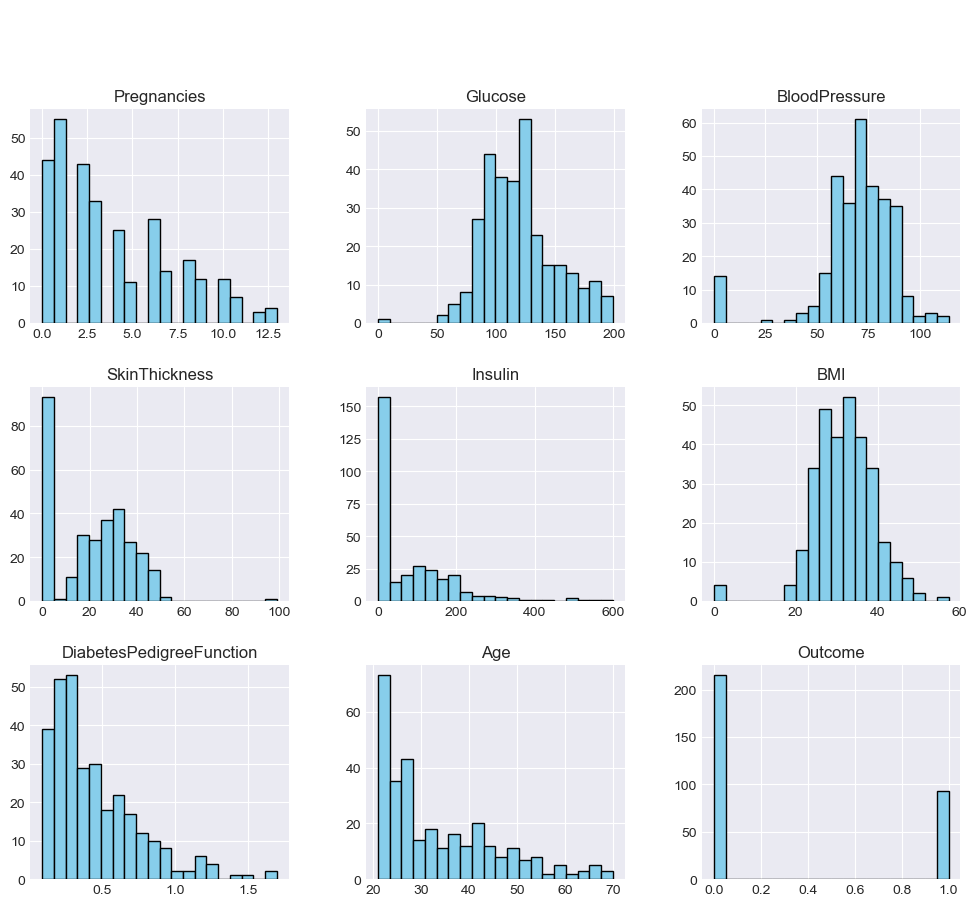

In [53]:
plt.style.use('dark_background')  
sns.set_style("darkgrid")  
df.hist(figsize=(12, 10), bins=20, edgecolor='black', color='skyblue') 
plt.suptitle('Distribution of All Variables', fontsize=16, color='white')  

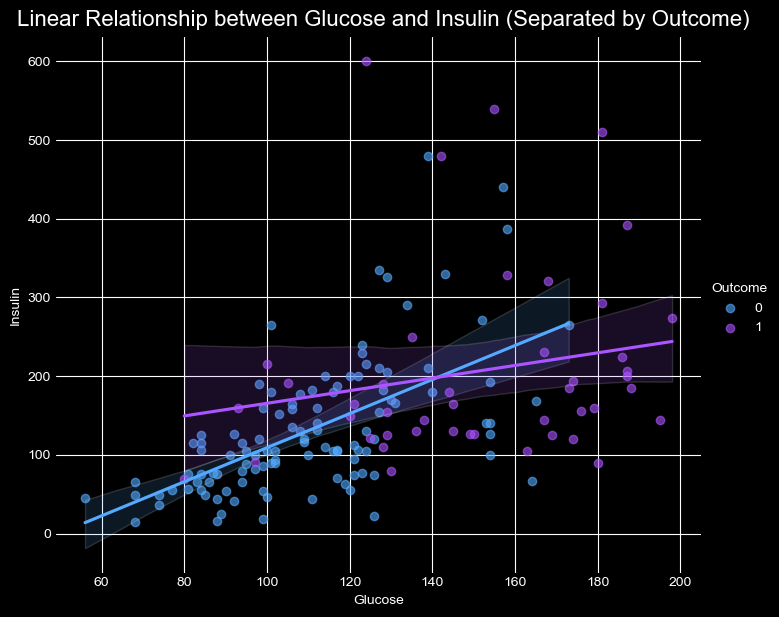

In [54]:
plt.style.use('dark_background') 
df_clean = df[(df['Insulin'] > 0) & (df['Glucose'] > 0)]
sns.lmplot(
    x='Glucose', 
    y='Insulin', 
    hue='Outcome',    
    data=df_clean,
    palette='cool',
    height=6,         
    aspect=1.2,
    scatter_kws={'alpha': 0.6} 
)

plt.suptitle('Linear Relationship between Glucose and Insulin (Separated by Outcome)', y=1.02, fontsize=16)
plt.show()

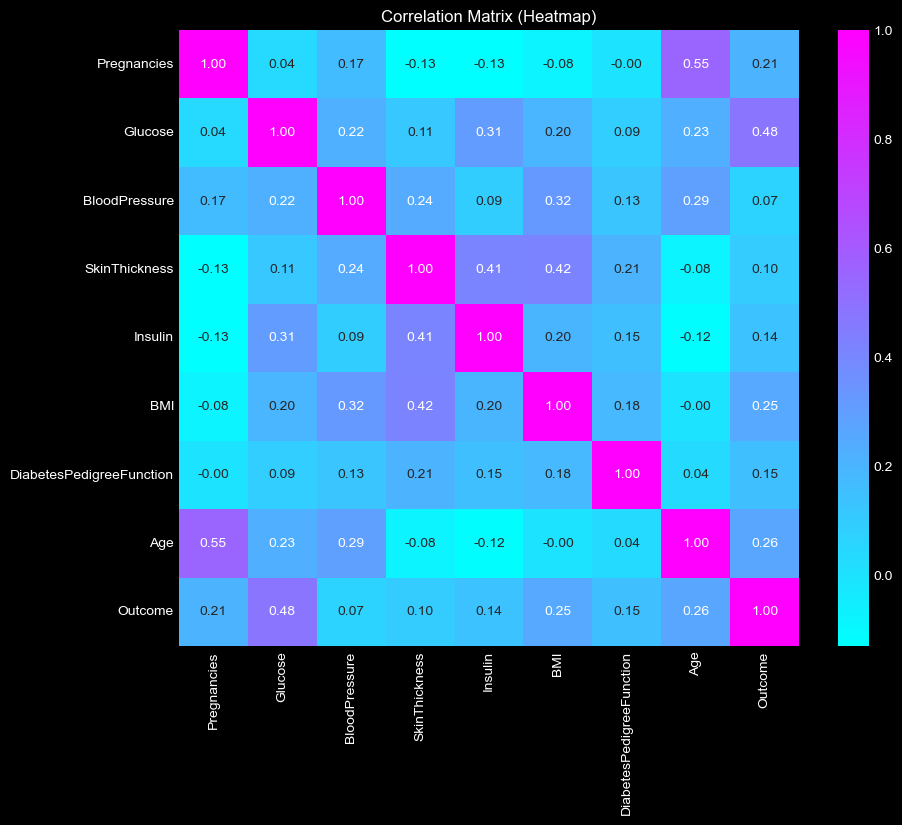

In [55]:
plt.style.use('dark_background') 
plt.figure(figsize=(10, 8))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='cool', fmt=".2f")
plt.title('Correlation Matrix (Heatmap)')
plt.show()

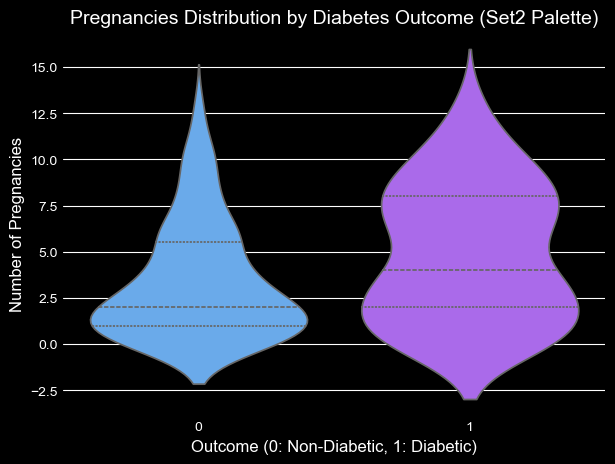

In [56]:
plt.figure(figsize=(7, 5))

sns.violinplot(
    x='Outcome',
    y='Pregnancies',
    data=df,
    palette='cool',
    inner='quartile' 
)

plt.title('Pregnancies Distribution by Diabetes Outcome (Set2 Palette)', fontsize=14)
plt.xlabel('Outcome (0: Non-Diabetic, 1: Diabetic)', fontsize=12)
plt.ylabel('Number of Pregnancies', fontsize=12)
plt.show()

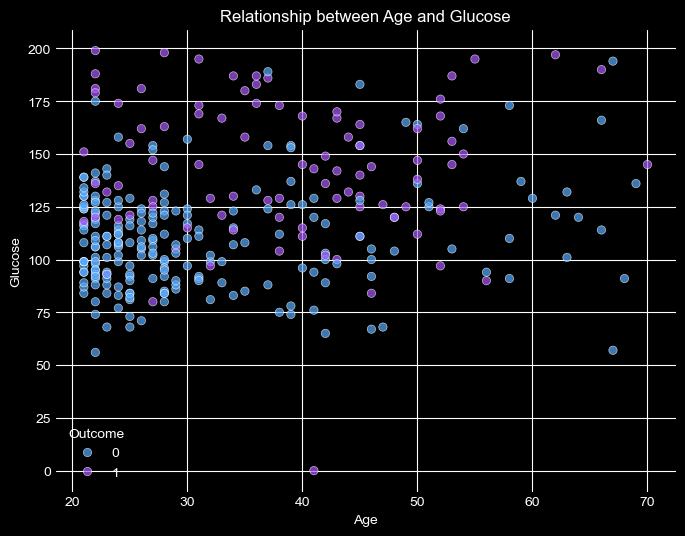

In [57]:
plt.figure(figsize=(8, 6))
sns.scatterplot(x='Age', y='Glucose', hue='Outcome', data=df, alpha=0.7,palette='cool')
plt.title('Relationship between Age and Glucose')
plt.show()

<Axes: >

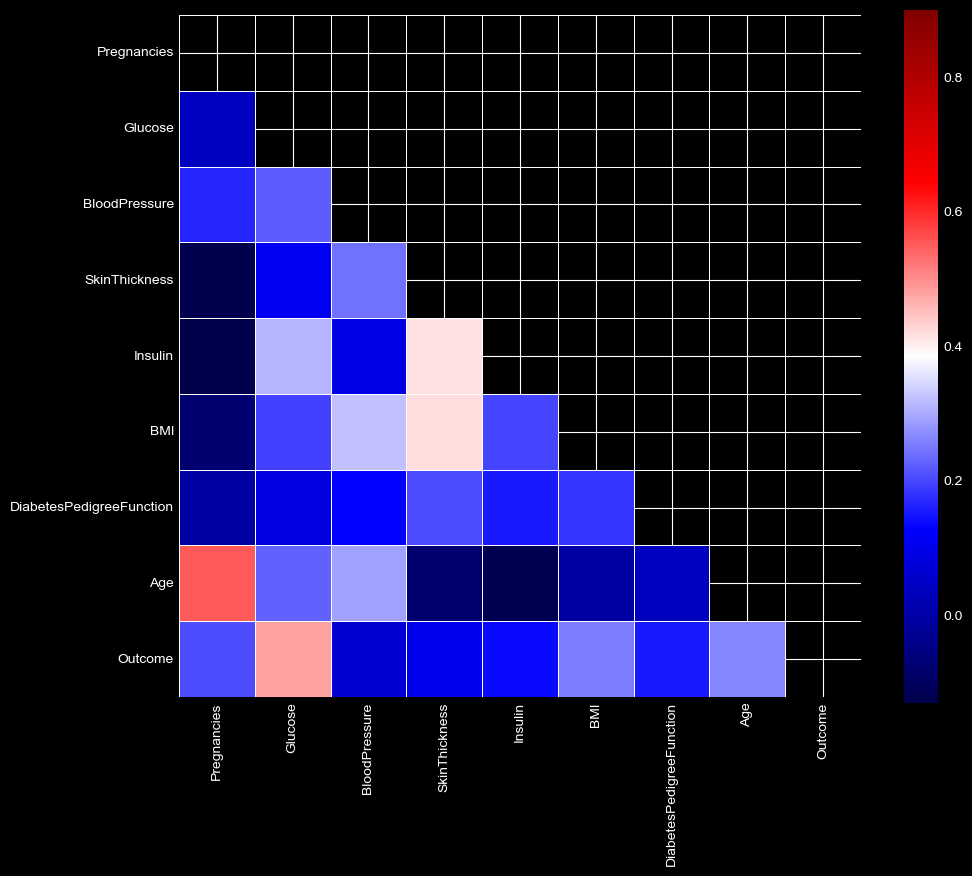

In [58]:
mask = np.zeros_like(df.corr(), dtype=bool)
mask[np.triu_indices_from(mask)] = True

f, ax = plt.subplots(figsize=(11, 9))

cmap = 'seismic'

sns.heatmap(df.corr(), mask=mask, cmap=cmap, vmax=.9, square=True, linewidths=.5, ax=ax)


In [59]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [61]:
model = LogisticRegression()
model.fit(X_train, y_train)

LogisticRegression()

In [62]:
y_pred = model.predict(X_test)


In [ ]:
print(y_train)

297    1
287    0
72     0
15     0
10     0
      ..
188    1
71     0
106    0
270    1
102    0
Name: Outcome, Length: 215, dtype: int64


In [65]:
print(y_test)

288    1
9      0
57     0
60     0
25     1
      ..
172    0
250    0
19     0
146    1
79     1
Name: Outcome, Length: 93, dtype: int64


In [63]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Accuracy:", accuracy_score(y_train, y_pred))

print(classification_report(y_test, y_pred))

KeyboardInterrupt: 